# Cheating Detection — YOLO Training

Train a YOLO model that detects **normal** and **cheating** students in exam videos.
The saved `best.pt` is used later in the Tkinter desktop app (`app.py`).

**Steps**
1. Install libraries
2. Import libraries
3. Download the dataset from Roboflow
4. Train the model
5. Evaluate on the test set
6. Check predictions on sample images
7. Save `best.pt`

> The Roboflow key is read from Kaggle Secrets (`ROBOFLOW_API_KEY`). Never upload it to GitHub.

## 1. Install Libraries

In [1]:
!pip install -q -U ultralytics roboflow

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


## 2. Import Libraries

In [2]:
import os
os.environ["WANDB_MODE"] = "disabled"

import glob
import random
import shutil
import matplotlib.pyplot as plt
from PIL import Image
from roboflow import Roboflow
from ultralytics import YOLO
from kaggle_secrets import UserSecretsClient   

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


## 3. Download the Dataset

In [3]:
API_KEY = UserSecretsClient().get_secret("ROBOFLOW_API_KEY")

rf = Roboflow(api_key=API_KEY)
project = rf.workspace("abdelaziz-vibr3").project("exam-malpractice-detection2-9pbpg-4wzua")
dataset = project.version(2).download("yolov8")

DATA_YAML = os.path.join(dataset.location, "data.yaml")
print("Dataset folder:", dataset.location)

for split in ["train", "valid", "test"]:
    n = len(glob.glob(os.path.join(dataset.location, split, "images", "*")))
    print(split, "->", n, "images")

loading Roboflow workspace...
loading Roboflow project...
Exporting format yolov8 in progress : 85.0%
Version export complete for yolov8 format



Extracting Dataset Version Zip to exam-malpractice-detection2-2 in yolov8:: 100%|██████████| 1822/1822 [00:00<00:00, 10609.94it/s]

Dataset folder: /kaggle/working/exam-malpractice-detection2-2
train -> 636 images
valid -> 182 images
test -> 91 images


## 4. Train the Model

- `imgsz=960` (bigger than 640) because phones and small movements are small objects.
- You can change `yolo11s.pt` to `yolo26n.pt` or `yolov8s.pt` to compare models.

In [4]:
EPOCHS = 50
IMAGE_SIZE = 960
BATCH_SIZE = 16

model = YOLO("yolo11s.pt")
model.train(
    data=DATA_YAML,
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    patience=15,
    seed=42,
    workers=2,
)

Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/exam-malpractice-detection2-2/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=Non

`get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.


       2/50      8.91G       1.33       1.44      1.346        162        960: 100% ━━━━━━━━━━━━ 40/40 2.6it/s 15.7s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 2.3it/s 2.6s
                   all        182       1307      0.318      0.641       0.41        0.2

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/50      8.86G      1.351      1.418      1.387        191        960: 100% ━━━━━━━━━━━━ 40/40 2.5it/s 16.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 2.1it/s 2.8s
                   all        182       1307      0.238      0.489      0.289      0.141

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/50      8.87G        1.4      1.461      1.439        176        960: 100% ━━━━━━━━━━━━ 40/40 2.3it/s 17.1s
                 Class     Images  Instances      Box(P        

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7bc2819f2ac0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

## 5. Evaluate on the Test Set

In [5]:
BEST_PATH = str(model.trainer.best)
best_model = YOLO(BEST_PATH)

metrics = best_model.val(data=DATA_YAML, split="test", imgsz=IMAGE_SIZE, plots=True)
print("mAP50    :", round(metrics.box.map50, 4))
print("mAP50-95 :", round(metrics.box.map, 4))
print("Precision:", round(metrics.box.mp, 4))
print("Recall   :", round(metrics.box.mr, 4))


names = best_model.names
for i, c in enumerate(metrics.box.ap_class_index):
    p, r, ap50, ap = metrics.box.class_result(i)
    print(f"{names[c]:10s} P={p:.3f}  R={r:.3f}  mAP50={ap50:.3f}  mAP50-95={ap:.3f}")

Ultralytics 8.4.192 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1292.8±404.1 MB/s, size: 49.4 KB)
val: Scanning /kaggle/working/exam-malpractice-detection2-2/test/labels... 91 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 91/91 1.3Kit/s 0.1s
val: New cache created: /kaggle/working/exam-malpractice-detection2-2/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 1.6it/s 3.9s
                   all         91        620       0.75      0.767      0.825      0.555
              cheating         85        264      0.766      0.712      0.795       0.51
                normal         67        356      0.734      0.823      0.856      0.599
Speed: 7.8ms preprocess, 22.0ms inference, 0.0ms loss, 1.2ms postprocess per image
Results saved to /kaggle/working/ru

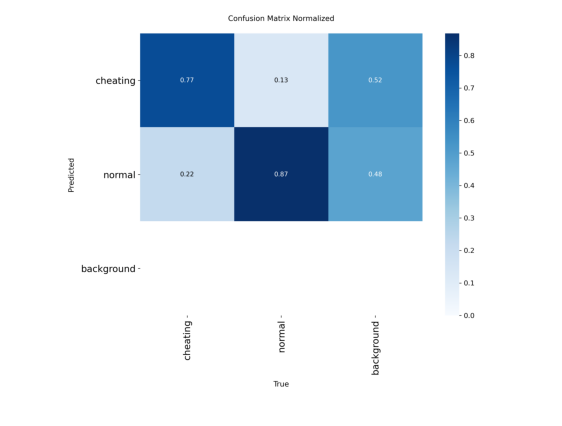

In [6]:
# confusion matrix
plt.figure(figsize=(7, 7))
plt.imshow(Image.open(os.path.join(str(metrics.save_dir), "confusion_matrix_normalized.png")))
plt.axis("off")
plt.show()

## 6. Check Predictions on Sample Images

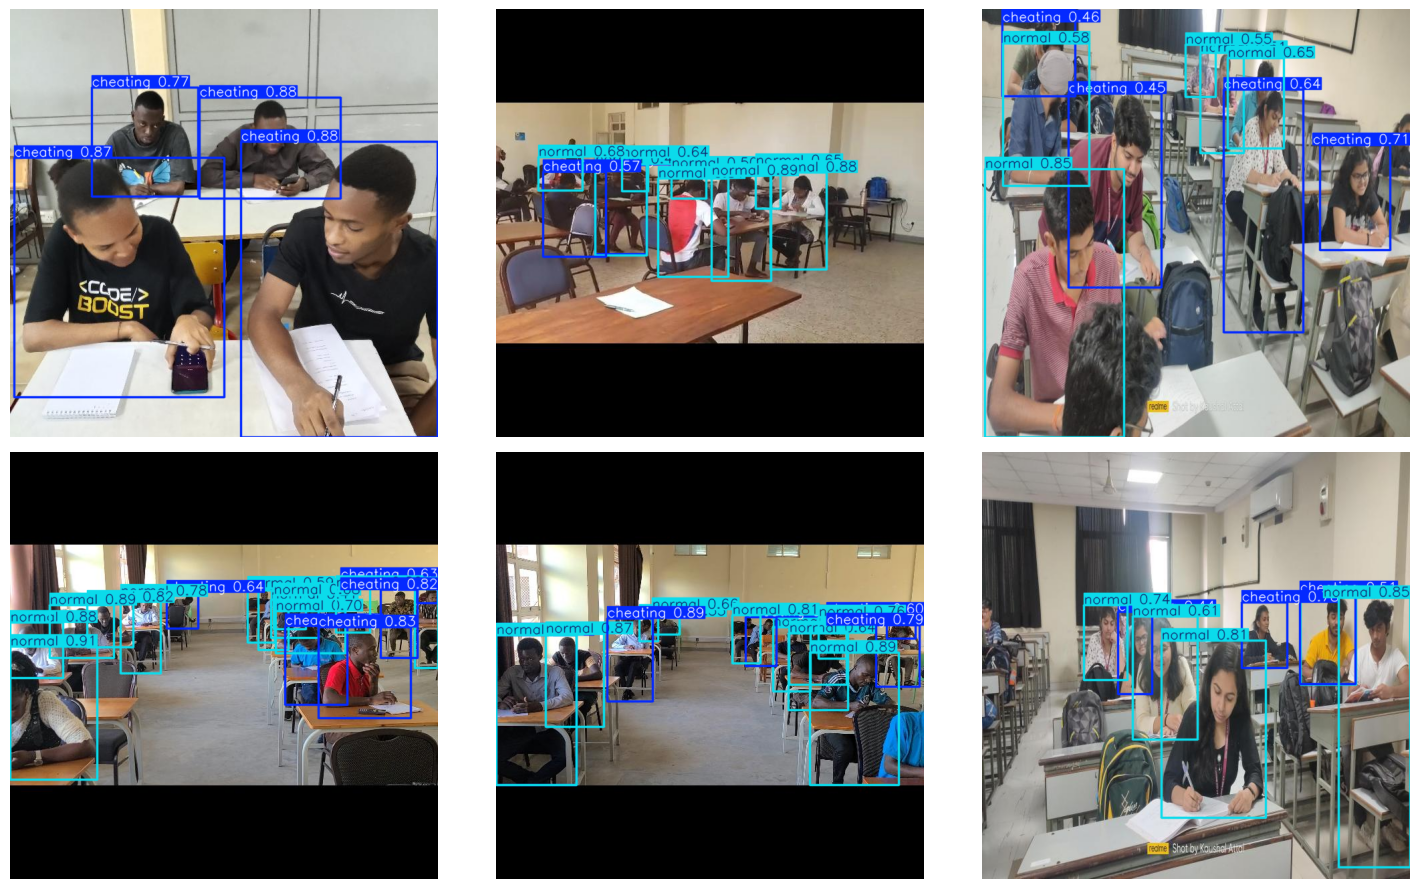

In [7]:
test_images = glob.glob(os.path.join(dataset.location, "test", "images", "*"))
samples = random.sample(test_images, min(6, len(test_images)))
preds = best_model.predict(samples, imgsz=IMAGE_SIZE, conf=0.4, verbose=False)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, result in zip(axes.flatten(), preds):
    ax.imshow(result.plot()[:, :, ::-1])   
    ax.axis("off")
plt.tight_layout()
plt.show()

## 7. Save the Model

Download `best.pt` from the Output tab and put it next to `app.py`. Do this before the session ends.

In [8]:
shutil.copy(BEST_PATH, "/kaggle/working/best.pt")
print("Saved: /kaggle/working/best.pt")

Saved: /kaggle/working/best.pt
